## South German Credit 불량 계약 예측

신용 계약의 대출 조건과 고객 정보 20개로 계약의 불량 여부를 예측한다. 한 행은 계약 한 건이며, 정답 `bad_credit`는 불량 1, 양호 0이다.

In [1]:
from io import BytesIO
from urllib.request import urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42

C:\Users\student\AppData\Local\uv\cache\archive-v0\hSihdx2D1NDdYIJy\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 데이터 준비

In [2]:
data_url = "https://archive.ics.uci.edu/static/public/573/south%2Bgerman%2Bcredit%2Bupdate.zip"
with urlopen(data_url, timeout=60) as response:
    archive_bytes = response.read()
with ZipFile(BytesIO(archive_bytes)) as archive:
    with archive.open("SouthGermanCredit.asc") as source:
        credit = pd.read_csv(source, sep=r"\s+")

column_names = {
    "laufkont": "status", "laufzeit": "duration", "moral": "credit_history",
    "verw": "purpose", "hoehe": "amount", "sparkont": "savings",
    "beszeit": "employment_duration", "rate": "installment_rate",
    "famges": "personal_status_sex", "buerge": "other_debtors",
    "wohnzeit": "present_residence", "verm": "property", "alter": "age",
    "weitkred": "other_installment_plans", "wohn": "housing",
    "bishkred": "number_credits", "beruf": "job", "pers": "people_liable",
    "telef": "telephone", "gastarb": "foreign_worker", "kredit": "credit_risk",
}
credit = credit.rename(columns=column_names)

category_names = {
    "status": {1: "no_account", 2: "negative_balance", 3: "balance_0_to_200_DM", 4: "balance_200_plus_or_salary"},
    "credit_history": {0: "past_payment_delay", 1: "critical_or_other_credit", 2: "no_credit_or_all_paid",
                       3: "existing_paid_to_date", 4: "all_paid_at_this_bank"},
    "purpose": {0: "other", 1: "new_car", 2: "used_car", 3: "furniture", 4: "radio_tv",
                5: "appliances", 6: "repairs", 7: "education", 8: "vacation", 9: "retraining", 10: "business"},
    "savings": {1: "unknown_or_no_account", 2: "below_100_DM", 3: "100_to_500_DM", 4: "500_to_1000_DM", 5: "1000_plus_DM"},
    "employment_duration": {1: "unemployed", 2: "below_1_year", 3: "1_to_4_years", 4: "4_to_7_years", 5: "7_plus_years"},
    "installment_rate": {1: "35_percent_plus", 2: "25_to_35_percent", 3: "20_to_25_percent", 4: "below_20_percent"},
    "personal_status_sex": {1: "male_divorced_or_separated", 2: "female_non_single_or_male_single",
                            3: "male_married_or_widowed", 4: "female_single"},
    "other_debtors": {1: "none", 2: "co_applicant", 3: "guarantor"},
    "present_residence": {1: "below_1_year", 2: "1_to_4_years", 3: "4_to_7_years", 4: "7_plus_years"},
    "property": {1: "unknown_or_no_property", 2: "car_or_other",
                 3: "building_society_savings_or_life_insurance", 4: "real_estate"},
    "other_installment_plans": {1: "bank", 2: "stores", 3: "none"},
    "housing": {1: "for_free", 2: "rent", 3: "own"},
    "number_credits": {1: "one", 2: "two_to_three", 3: "four_to_five", 4: "six_plus"},
    "job": {1: "unemployed_or_unskilled_non_resident", 2: "unskilled_resident",
            3: "skilled_employee_or_official", 4: "manager_self_employed_or_highly_qualified"},
    "people_liable": {1: "three_plus", 2: "zero_to_two"},
    "telephone": {1: "no", 2: "yes_under_customer_name"},
    "foreign_worker": {1: "yes", 2: "no"},
}
for column, mapping in category_names.items():
    credit[column] = credit[column].map(mapping)
credit["bad_credit"] = 1 - credit["credit_risk"]

CREDIT_NUMERIC = ["duration", "amount", "age"]
CREDIT_CATEGORICAL = list(category_names)
CREDIT_FEATURES = CREDIT_NUMERIC + CREDIT_CATEGORICAL
X = credit[CREDIT_FEATURES]
y = credit["bad_credit"]

print("X:", X.shape, "y:", y.shape)
display(pd.concat([X, y], axis=1).head())

X: (1000, 20) y: (1000,)


,duration,amount,age,status,credit_history,purpose,savings,employment_duration,installment_rate,personal_status_sex,...,present_residence,property,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,bad_credit
0,18,1049,21,no_account,all_paid_at_this_bank,used_car,unknown_or_no_account,below_1_year,below_20_percent,female_non_single_or_male_single,...,7_plus_years,car_or_other,none,for_free,one,skilled_employee_or_official,zero_to_two,no,no,0
1,9,2799,36,no_account,all_paid_at_this_bank,other,unknown_or_no_account,1_to_4_years,25_to_35_percent,male_married_or_widowed,...,1_to_4_years,unknown_or_no_property,none,for_free,two_to_three,skilled_employee_or_official,three_plus,no,no,0
2,12,841,23,negative_balance,no_credit_or_all_paid,retraining,below_100_DM,4_to_7_years,25_to_35_percent,female_non_single_or_male_single,...,7_plus_years,unknown_or_no_property,none,for_free,one,unskilled_resident,zero_to_two,no,no,0
3,12,2122,39,no_account,all_paid_at_this_bank,other,unknown_or_no_account,1_to_4_years,20_to_25_percent,male_married_or_widowed,...,1_to_4_years,unknown_or_no_property,none,for_free,two_to_three,unskilled_resident,three_plus,no,yes,0
4,12,2171,38,no_account,all_paid_at_this_bank,other,unknown_or_no_account,1_to_4_years,below_20_percent,male_married_or_widowed,...,7_plus_years,car_or_other,bank,rent,two_to_three,unskilled_resident,zero_to_two,no,yes,0


### 학습·검증·테스트 분리

In [3]:
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED,
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_development, y_development, test_size=0.25,
    stratify=y_development, random_state=SEED,
)

display(pd.DataFrame([
    {"split": name, "contracts": len(labels), "bad": int(labels.sum()), "bad_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_valid), ("test", y_test)]
]))

,split,contracts,bad,bad_rate
0,train,600,180,0.3
1,validation,200,60,0.3
2,test,200,60,0.3


### 기준 모델

기준 설정은 로지스틱 회귀 `C=1.0`, 랜덤포레스트 트리 200개·최대 깊이 6·잎당 최소 학습 계약 5건이다. 변경 실험에서도 아래 함수로 모델을 만들고, 바꾸는 설정만 인자로 전달한다.

비교 지표는 검증 데이터의 ROC AUC와 임계값 0.5에서의 정밀도·재현율·혼동 행렬 건수다. 학습 ROC AUC는 학습·검증 점수의 차이를 확인하는 데 사용한다.

In [4]:
def make_logistic(C=1.0, numeric=CREDIT_NUMERIC, categorical=CREDIT_CATEGORICAL):
    preprocessor = ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])


def make_forest(numeric=CREDIT_NUMERIC, categorical=CREDIT_CATEGORICAL, **forest_params):
    params = dict(
        n_estimators=200, max_depth=6, min_samples_leaf=5,
        max_features="sqrt", random_state=SEED, n_jobs=-1,
    )
    params.update(forest_params)
    preprocessor = ColumnTransformer([
        ("numeric", "passthrough", numeric),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(**params)),
    ])


def bad_scores(model, inputs):
    positive_column = list(model.classes_).index(1)
    return model.predict_proba(inputs)[:, positive_column]


def credit_metrics(actual, scores, threshold=0.5):
    prediction = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, prediction, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(actual, scores),
        "precision": precision_score(actual, prediction, zero_division=0),
        "recall": recall_score(actual, prediction, zero_division=0),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }


models = {}
valid_scores = {}
model_results = {}


def fit_and_evaluate(name, model):
    model.fit(X_train, y_train)
    models[name] = model
    valid_scores[name] = bad_scores(model, X_valid)
    model_results[name] = {
        "model": name,
        "train_roc_auc": roc_auc_score(y_train, bad_scores(model, X_train)),
        **credit_metrics(y_valid, valid_scores[name]),
    }
    return model_results[name]


fit_and_evaluate("logistic_C1", make_logistic())
fit_and_evaluate("forest_depth6", make_forest())
display(pd.DataFrame(model_results.values()).round(3))

,model,train_roc_auc,roc_auc,precision,recall,TP,FP,FN,TN
0,logistic_C1,0.854,0.800,0.604,0.533,32,21,28,119
1,forest_depth6,0.927,0.805,0.647,0.183,11,6,49,134


## 추가 실험

### 로지스틱 회귀의 규제 강도 비교

원핫 인코딩 후 입력은 60개가 넘고 학습 계약은 600건이다. 표본이 적은 범주의 원핫 열에는 학습 데이터에 맞춘 큰 계수가 생길 수 있다. 다른 설정은 유지하고 `C`를 1.0에서 0.3·0.1로 줄여 규제를 강하게 한다. 계수 절댓값의 평균으로 계수가 작아지는 정도를 함께 확인한다.

In [5]:
regularization_rows = []
for c_value in [1.0, 0.3, 0.1]:
    name = f"logistic_C{c_value:g}"
    if name not in models:
        fit_and_evaluate(name, make_logistic(C=c_value))
    coefficients = models[name].named_steps["model"].coef_[0]
    regularization_rows.append({
        **model_results[name],
        "mean_abs_coefficient": np.abs(coefficients).mean(),
    })

display(pd.DataFrame(regularization_rows).round(3))

,model,train_roc_auc,roc_auc,precision,recall,TP,FP,FN,TN,mean_abs_coefficient
0,logistic_C1,0.854,0.800,0.604,0.533,32,21,28,119,0.326
1,logistic_C0.3,0.851,0.805,0.600,0.550,33,22,27,118,0.248
2,logistic_C0.1,0.843,0.807,0.633,0.517,31,18,29,122,0.172


### 규제 강도 비교 결과

`C`를 1.0에서 0.1로 줄이면 계수 절댓값의 평균은 약 0.326에서 0.172로 작아지고, 학습 ROC AUC는 0.854에서 0.843으로 낮아진다. 검증 ROC AUC는 0.800에서 0.807로 조금 높아진다. 계수가 작아지면서 학습 데이터에 맞춘 정도가 줄었고, 이번 분할에서는 검증 점수가 조금 높아졌다.

임계값 0.5에서 `C=0.1`은 FP가 21건에서 18건으로 줄고 FN이 28건에서 29건으로 늘어, 정밀도는 약 0.604에서 0.633으로 높아지고 재현율은 약 0.533에서 0.517로 낮아졌다. 검증 ROC AUC의 차이는 0.01 이내로 작다.

### 랜덤포레스트의 최대 깊이 비교

다른 설정은 유지하고 `max_depth`를 6에서 3과 제한 없음(`None`)으로 바꾼다. 트리가 얕으면 각 잎에 여러 계약이 모여 점수가 평균에 가까워지고, 깊으면 학습 계약의 세부 조합까지 나누어 학습한다.

In [6]:
depth_rows = []
for depth in [3, 6, None]:
    name = f"forest_depth{depth}" if depth is not None else "forest_unlimited"
    if name not in models:
        fit_and_evaluate(name, make_forest(max_depth=depth))
    forest_scores = valid_scores[name]
    depth_rows.append({
        **model_results[name],
        # 검증 계약의 불량 점수 범위.
        "min_score": forest_scores.min(),
        "max_score": forest_scores.max(),
    })

display(pd.DataFrame(depth_rows).round(3))

,model,train_roc_auc,roc_auc,precision,recall,TP,FP,FN,TN,min_score,max_score
0,forest_depth3,0.858,0.810,0.000,0.000,0,0,60,140,0.135,0.498
1,forest_depth6,0.927,0.805,0.647,0.183,11,6,49,134,0.059,0.625
2,forest_unlimited,0.962,0.806,0.588,0.333,20,14,40,126,0.030,0.644


### 최대 깊이 비교 결과

깊이 3은 학습 ROC AUC가 0.858로 가장 낮고 검증 ROC AUC는 0.810으로 가장 높다. 검증 계약의 불량 점수가 최대 0.498이어서 임계값 0.5에서는 불량으로 예측한 계약이 없고, 정밀도와 재현율이 모두 0이다. 얕은 트리의 잎에는 양호와 불량이 섞여 있어 잎의 불량 비율이 0이나 1에 가까워지기 어렵고, 200개 트리를 평균한 검증 점수는 0.135~0.498 범위에 머문다.

깊이 제한을 없애면 학습 ROC AUC는 0.962로 높아지지만 검증 ROC AUC는 0.806으로 깊이 6과 비슷하다. 학습 데이터의 세부 조합까지 나누어 학습했지만, 검증 계약의 순위는 거의 개선되지 않았다.

세 깊이의 검증 ROC AUC 차이는 0.005 이내이고, 점수의 범위는 크게 다르다. 임계값 0.5의 정밀도·재현율은 점수의 범위에 따라 크게 달라지고, ROC AUC는 계약 사이의 점수 순위만 반영한다.

### 중요도가 낮은 변수 제외

랜덤포레스트의 특성 중요도는 원핫 열마다 계산된다. 같은 원래 변수에서 만든 원핫 열의 중요도를 더해 변수 단위로 비교하고, 중요도가 가장 낮은 변수 5개를 입력에서 제외한다. 하이퍼파라미터는 기준 랜덤포레스트와 같다.

In [7]:
base_forest = models["forest_depth6"]
forest_feature_names = base_forest.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(
    base_forest.named_steps["model"].feature_importances_, index=forest_feature_names,
)


def original_variable(feature_name):
    # "category__purpose_new_car" → "purpose"
    transformed_name = feature_name.split("__", 1)[1]
    for column in CREDIT_FEATURES:
        if transformed_name == column or transformed_name.startswith(column + "_"):
            return column


variable_importance = importance.groupby(original_variable).sum().sort_values()
display(variable_importance.head(8).to_frame("importance").round(4))

dropped_variables = list(variable_importance.index[:5])
kept_numeric = [column for column in CREDIT_NUMERIC if column not in dropped_variables]
kept_categorical = [column for column in CREDIT_CATEGORICAL if column not in dropped_variables]
print("제외한 변수:", dropped_variables)

fit_and_evaluate(
    "forest_drop5",
    make_forest(numeric=kept_numeric, categorical=kept_categorical),
)
display(pd.DataFrame([
    model_results["forest_depth6"], model_results["forest_drop5"],
]).round(3))

,importance
other_debtors,0.0044
foreign_worker,0.0068
people_liable,0.0074
number_credits,0.0169
present_residence,0.0181
telephone,0.0222
job,0.0241
other_installment_plans,0.0252


제외한 변수: ['other_debtors', 'foreign_worker', 'people_liable', 'number_credits', 'present_residence']


,model,train_roc_auc,roc_auc,precision,recall,TP,FP,FN,TN
0,forest_depth6,0.927,0.805,0.647,0.183,11,6,49,134
1,forest_drop5,0.923,0.808,0.762,0.267,16,5,44,135


### 변수 제외 결과

중요도가 가장 낮은 5개 변수의 중요도 합은 약 0.054이며, 입력 변수는 20개에서 15개로 줄었다. 검증 ROC AUC는 0.805에서 0.808로 비슷하고, 임계값 0.5에서 TP는 11건에서 16건으로 늘고 FP는 6건에서 5건으로 줄었다.

원핫 열이 줄면 각 분할에서 무작위로 고르는 후보 열의 구성도 달라지므로, 임계값 0.5의 건수 변화에는 이 영향이 함께 반영된다. 중요도는 이 모델이 분할에 사용한 정도를 나타내므로, 이 결과는 이 모델과 이 분할에 한정해 해석한다.

## 모델과 임계값 선택

### 모델 선택

임계값을 정하기 전에 검증 ROC AUC가 가장 높은 모델을 선택한다. 동점이면 먼저 학습한 모델을 사용한다.

In [8]:
model_comparison = pd.DataFrame(model_results.values()).sort_values(
    "roc_auc", ascending=False, kind="stable",
)
display(model_comparison.round(3))

selected_name = model_comparison.iloc[0]["model"]
selected_model = models[selected_name]
selected_scores = valid_scores[selected_name]
print("선택한 모델:", selected_name)

,model,train_roc_auc,roc_auc,precision,recall,TP,FP,FN,TN
4,forest_depth3,0.858,0.810,0.000,0.000,0,0,60,140
6,forest_drop5,0.923,0.808,0.762,0.267,16,5,44,135
3,logistic_C0.1,0.843,0.807,0.633,0.517,31,18,29,122
5,forest_unlimited,0.962,0.806,0.588,0.333,20,14,40,126
1,forest_depth6,0.927,0.805,0.647,0.183,11,6,49,134
2,logistic_C0.3,0.851,0.805,0.600,0.550,33,22,27,118
0,logistic_C1,0.854,0.800,0.604,0.533,32,21,28,119


선택한 모델: forest_depth3


### 임계값 선택

불량 계약을 놓치면 빌려준 돈을 회수하지 못하므로, 검증 데이터의 불량 계약 중 80% 이상을 찾는 것을 조건으로 둔다. 재현율이 0.8 이상인 임계값 중 정밀도가 가장 높은 값을 선택하고, 동점이면 더 낮은 임계값을 사용한다. 재현율 기준 0.8은 이 답안에서 정한 값이며, 기준을 바꾸면 선택되는 임계값도 달라진다.

In [9]:
MIN_RECALL = 0.8

threshold_rows = []
for threshold in np.arange(0.10, 0.51, 0.05).round(2):
    metrics = credit_metrics(y_valid, selected_scores, threshold)
    threshold_rows.append({"threshold": threshold, **metrics})
threshold_table = pd.DataFrame(threshold_rows).drop(columns="roc_auc")
display(threshold_table.round(3))

# 재현율 조건을 만족하는 임계값 중 정밀도가 가장 높은 행을 고른다.
eligible = threshold_table[threshold_table["recall"] >= MIN_RECALL]
selected_threshold = float(eligible.loc[eligible["precision"].idxmax(), "threshold"])
print("선택한 임계값:", selected_threshold)

,threshold,precision,recall,TP,FP,FN,TN
0,0.10,0.300,1.000,60,140,0,0
1,0.15,0.303,1.000,60,138,0,2
2,0.20,0.343,1.000,60,115,0,25
3,0.25,0.396,0.950,57,87,3,53
4,0.30,0.473,0.883,53,59,7,81
5,0.35,0.594,0.683,41,28,19,112
6,0.40,0.647,0.367,22,12,38,128
7,0.45,0.857,0.100,6,1,54,139
8,0.50,0.000,0.000,0,0,60,140


선택한 임계값: 0.3


### 임계값 선택 결과

재현율 0.8 이상을 만족하는 임계값은 0.10~0.30이고, 이 중 0.3의 정밀도가 약 0.473으로 가장 높다. 검증 불량 60건 중 53건을 찾고 7건을 놓쳐 재현율은 약 0.883이며, 양호 140건 중 59건을 불량으로 판단한다. 임계값을 0.35로 올리면 FP는 59건에서 28건으로 줄어 정밀도가 약 0.594로 높아지지만, FN이 7건에서 19건으로 늘어 재현율이 약 0.683으로 기준보다 낮아진다.

선택한 모델은 검증 점수가 모두 0.5보다 낮으므로, 임계값 0.5를 그대로 적용하면 불량 계약을 찾지 못한다.

### 검증 ROC·PR 곡선과 선택한 임계값

두 기준 모델과 선택한 모델의 곡선을 비교한다. 검은 점은 선택한 모델에 선택한 임계값을 적용한 위치다.

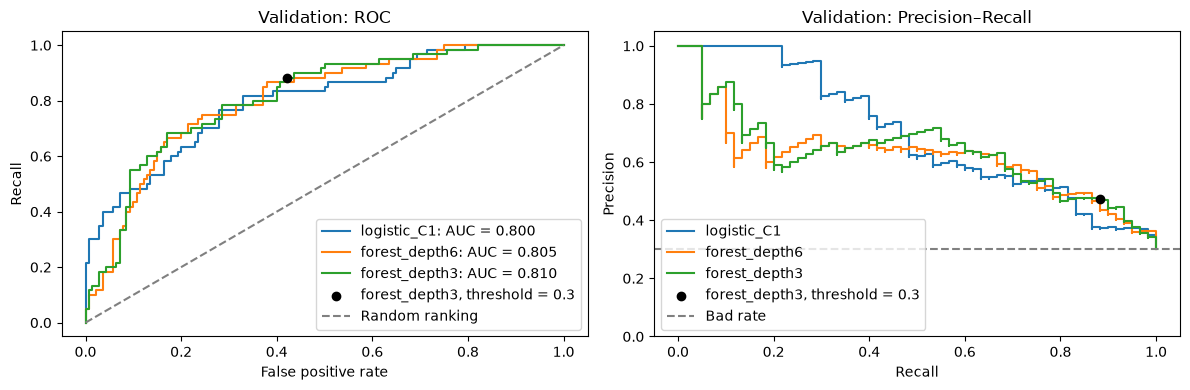

In [10]:
curve_names = list(dict.fromkeys(["logistic_C1", "forest_depth6", selected_name]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in curve_names:
    scores = valid_scores[name]
    fpr, tpr, _ = roc_curve(y_valid, scores)
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    axes[0].plot(fpr, tpr, label=f"{name}: AUC = {roc_auc_score(y_valid, scores):.3f}")
    axes[1].step(recall, precision, where="post", label=name)

point = credit_metrics(y_valid, selected_scores, selected_threshold)
point_fpr = point["FP"] / (point["FP"] + point["TN"])
point_label = f"{selected_name}, threshold = {selected_threshold:g}"
axes[0].scatter(point_fpr, point["recall"], color="black", zorder=3, label=point_label)
axes[1].scatter(point["recall"], point["precision"], color="black", zorder=3, label=point_label)

axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[0].set(xlabel="False positive rate", ylabel="Recall", title="Validation: ROC")
axes[0].legend()
axes[1].axhline(y_valid.mean(), linestyle="--", color="gray", label="Bad rate")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Validation: Precision–Recall", ylim=(0, 1.05))
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

재현율 0.2~0.4 구간에서 로지스틱 회귀의 정밀도는 약 0.8 이상으로, 두 랜덤포레스트의 약 0.6~0.7보다 높다. 점수가 가장 높은 소수의 계약을 고를 때는 로지스틱 회귀의 순위가 더 정확하다. 선택한 임계값이 놓인 재현율 약 0.88에서는 두 랜덤포레스트의 정밀도가 약 0.47, 로지스틱 회귀가 약 0.38이다. ROC AUC는 모든 임계값을 하나의 값으로 요약하므로, 사용할 재현율 구간의 정밀도를 함께 확인한다.

### 최종 테스트

선택한 모델과 임계값을 테스트 데이터에 한 번 적용하고, 같은 설정의 검증 결과와 비교한다.

선택 모델: forest_depth3, 임계값=0.3


,split,roc_auc,precision,recall,TP,FP,FN,TN
0,validation,0.810,0.473,0.883,53,59,7,81
1,test,0.745,0.430,0.767,46,61,14,79


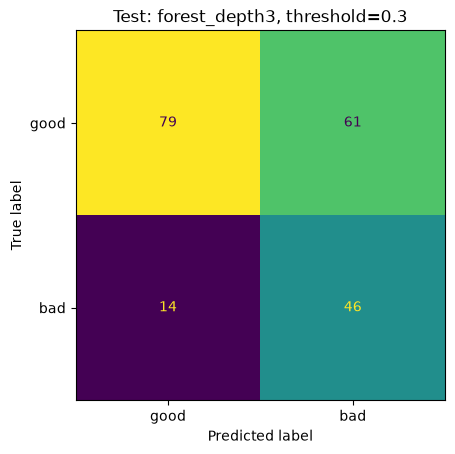

In [11]:
test_scores = bad_scores(selected_model, X_test)
final_comparison = pd.DataFrame([
    {"split": "validation", **credit_metrics(y_valid, selected_scores, selected_threshold)},
    {"split": "test", **credit_metrics(y_test, test_scores, selected_threshold)},
])
print(f"선택 모델: {selected_name}, 임계값={selected_threshold:g}")
display(final_comparison.round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, (test_scores >= selected_threshold).astype(int), labels=[0, 1],
    display_labels=["good", "bad"], colorbar=False,
)
plt.title(f"Test: {selected_name}, threshold={selected_threshold:g}")
plt.show()

### 결과 해석과 한계

테스트 ROC AUC는 0.745로 검증의 0.810보다 낮다. 임계값 0.3에서 테스트 불량 60건 중 46건을 찾고 14건을 놓쳐 재현율은 약 0.767이며, 양호 140건 중 61건을 불량으로 판단해 정밀도는 약 0.430이다. 검증과 비교하면 FN은 7건에서 14건으로 늘었고, 테스트 재현율은 기준으로 정한 0.8보다 낮다.

후보 모델의 검증 ROC AUC는 0.800~0.810으로 차이가 0.01 정도이고, 선택한 모델의 검증·테스트 ROC AUC 차이는 0.065다. 계약 200건(불량 60건)으로 한 번 평가한 결과에서는 0.01 정도의 차이로 후보의 우열을 판단하기 어렵다. 임계값도 같은 검증 계약에 맞춰 골랐으므로 테스트 재현율이 검증보다 낮게 나올 수 있다. 여러 분할에서 후보를 비교하는 교차 검증을 사용하면 분할에 따른 변동을 함께 확인할 수 있다.

재현율 기준 0.8은 이 답안에서 정한 값이다. 실제 신용평가에서는 대출 금액과 회수 가능성에 따라 놓친 불량 계약의 손실이 계약마다 다르므로, 이런 정보를 함께 고려해 기준을 정한다. 데이터는 1973~1975년의 계약이므로 현재 고객에게 적용하려면 최근 데이터로 다시 검증해야 한다.

## 테스트 데이터의 SHAP 분석

확정한 모델이 테스트 계약 200건의 불량 점수를 계산할 때 각 입력이 어떻게 반영되었는지 확인한다.

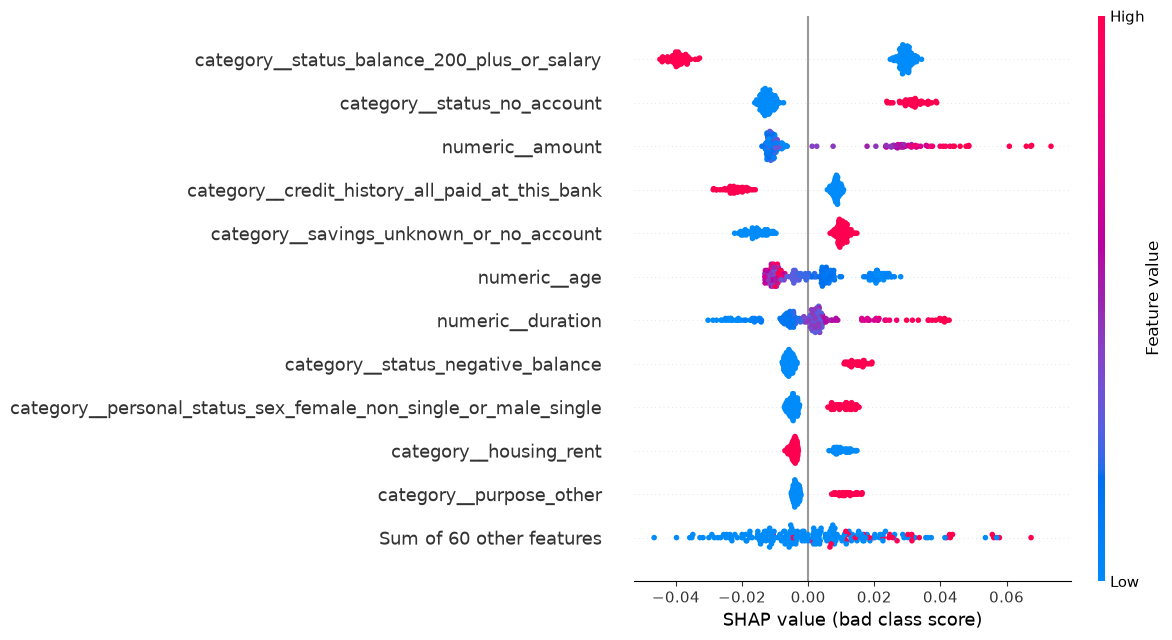

In [12]:
selected_preprocessor = selected_model.named_steps["preprocess"]
selected_forest = selected_model.named_steps["model"]
test_values = selected_preprocessor.transform(X_test)

test_explainer = shap.TreeExplainer(
    selected_forest, feature_perturbation="tree_path_dependent", model_output="raw",
)
positive_column = list(selected_forest.classes_).index(1)
test_explanation = test_explainer(test_values)[:, :, positive_column]
test_explanation.feature_names = list(selected_preprocessor.get_feature_names_out())

shap.plots.beeswarm(test_explanation, max_display=12, show=False)
plt.xlabel("SHAP value (bad class score)")
plt.gcf().set_size_inches(12, 6.5)
plt.tight_layout()
plt.show()

점 분포를 보면 다음과 같이 해석할 수 있다.

- `status`의 원핫 열 두 개가 가장 위에 있다. 잔액이 200 DM 이상이거나 급여 계좌인 계약은 불량 점수를 낮추고, 계좌가 없는 계약은 높인다. 계좌 상태가 이 모델의 점수에 가장 크게 반영된다.
- `numeric__amount`와 `numeric__duration`은 빨간 점이 오른쪽에 있다. 금액이 크고 기간이 긴 계약일수록 불량 점수를 높이는 방향으로 반영된다.
- `category__credit_history_all_paid_at_this_bank`는 빨간 점이 왼쪽에 있다. 이 은행의 기존 계약을 모두 상환한 이력은 불량 점수를 낮추는 방향으로 반영된다.